# 05 · Companies

Who hires for IT in Vietnam, and is hiring concentrated or spread out?

**Method.** Company names are normalised (`taxonomy.company_key`): legal suffixes, branch notes and punctuation are dropped, so spelling variants of one employer line up. The 2020 feed has no company field and only 44 % of 2021 postings name one, so company analysis uses **2021 on, and 2021 is flagged**. Distinct-company counts grow with the number of postings, so concentration (the share held by the biggest employers) is the fairer measure. Banks and recruitment agencies are found by keyword in the name, an approximation.

In [1]:
from vnjobs.analysis import companies as c
from vnjobs.analysis import core as a

a.apply_style()
con = a.connect()
df = a.load_features(con)

In [2]:
named = c.named(df)
coverage = c.coverage_by_year(df)
a.save_table(coverage, "05-company-coverage")
print(f"{len(named):,} postings name a company (2021 on)")
coverage

142,200 postings name a company (2021 on)


,year,postings,pct_company_named
0,2020,6643,0.0
1,2021,12214,42.1
2,2022,9547,100.0
3,2023,25503,100.0
4,2024,31141,99.9
5,2025,34478,99.9
6,2026,36477,100.0


## 1. The biggest hirers

Employers with the most unique IT postings. Recent window (2025 to October 2026) first, then 2021–22 for contrast.

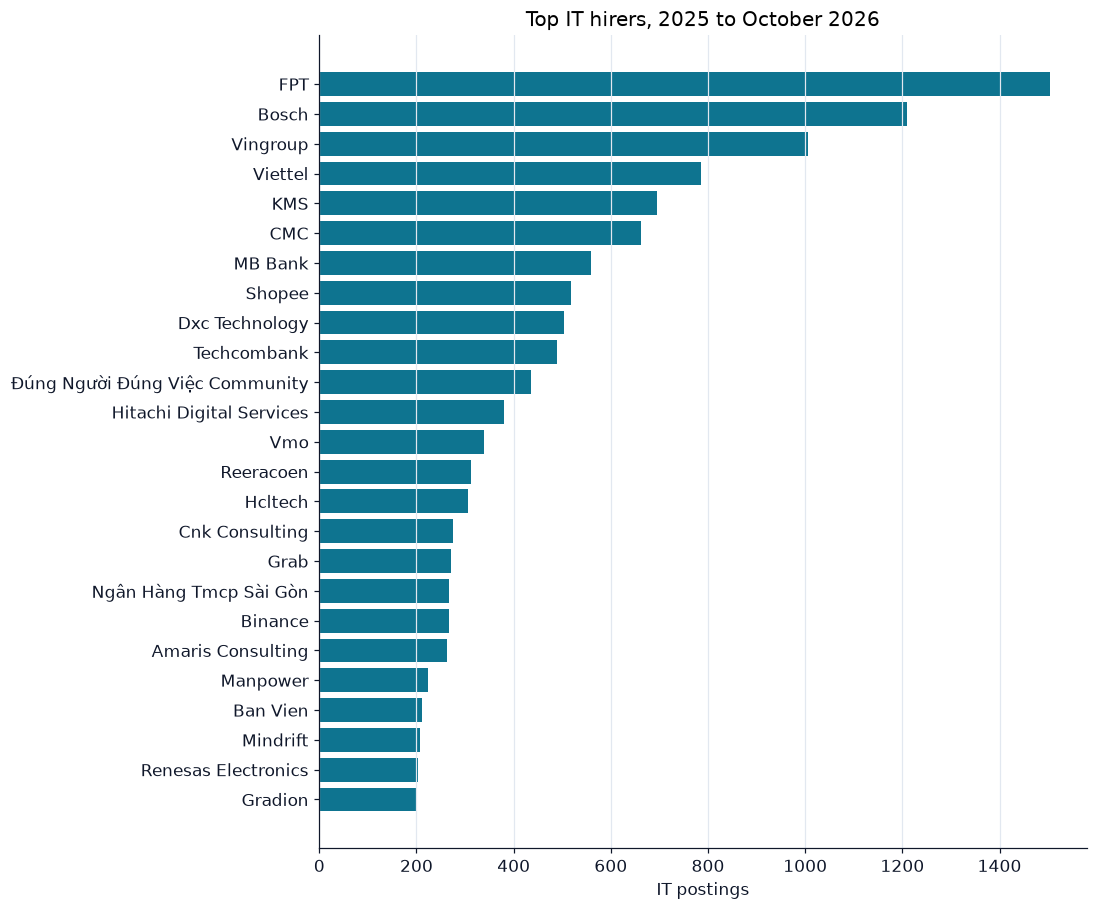

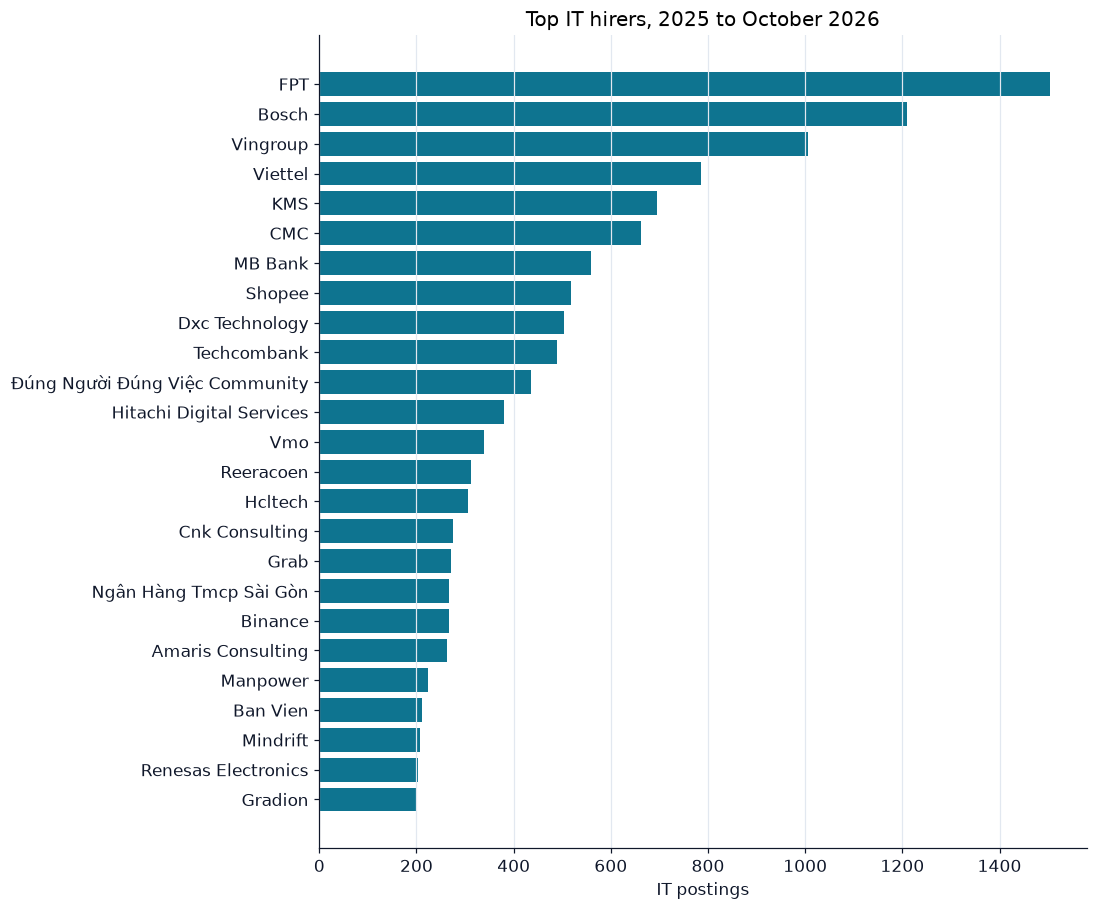

In [3]:
recent = c.top_hirers(named, "2025-01", "2026-10")
a.save_table(recent, "05-top-hirers-2025-2026")
fig = a.barh(recent, "company", "postings", "Top IT hirers, 2025 to October 2026", "IT postings")
a.save_chart(fig, "05-top-hirers-recent")
fig

In [4]:
early = c.top_hirers(named, "2021-01", "2022-12")
a.save_table(early, "05-top-hirers-2021-2022")
early

,company,postings,share
0,FPT,680,4.63
1,CMC,345,2.35
2,Viettel,230,1.57
3,Ngân Hàng Tmcp Sài Gòn,193,1.31
4,Mtv Wacontre,186,1.27
5,MB Bank,155,1.06
6,Chứng Khoán Vndirect,150,1.02
7,Hitachi Lifts And Elevators,150,1.02
8,Persolkelly,149,1.01
9,Rgf Hr Agent,118,0.80


## 2. How concentrated hiring is

Per year: how many employers, the share of postings from the ten biggest, and the share of employers that posted only once.

In [5]:
concentration = c.concentration_by_year(named)
a.save_table(concentration, "05-concentration")
concentration

,year,postings,companies,top10_share,pct_companies_posting_once
0,2021,5138,1217,15.4,43.2
1,2022,9544,1962,12.5,42.2
2,2023,25492,7312,7.2,54.2
3,2024,31111,8664,9.4,54.6
4,2025,34454,9005,7.6,52.9
5,2026,36461,5125,9.3,39.3


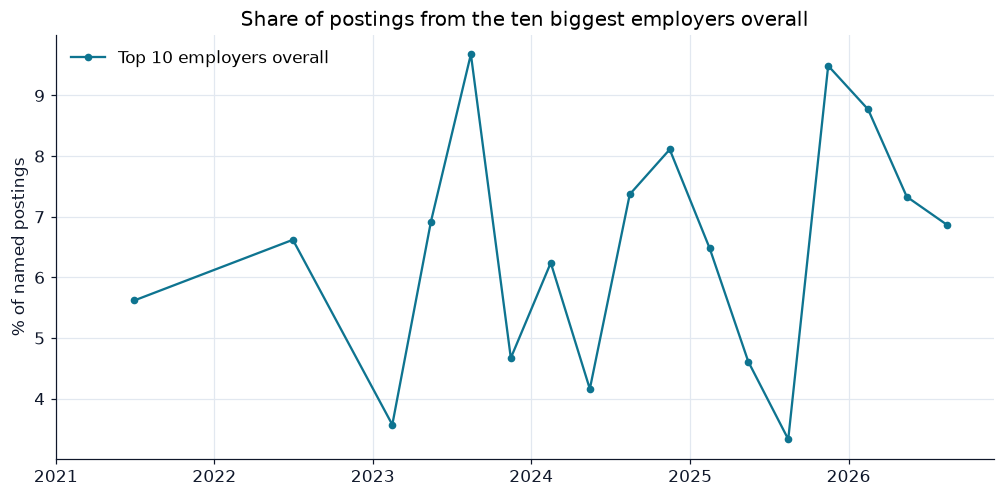

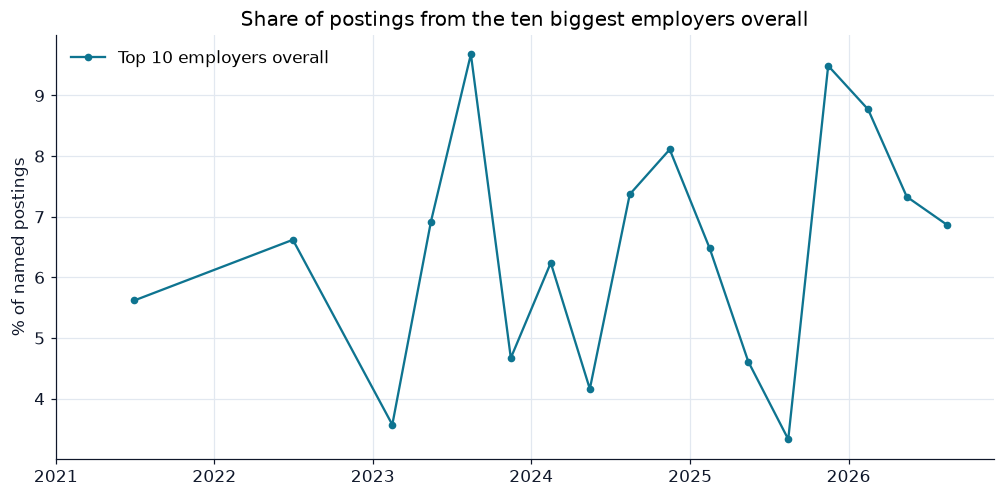

In [6]:
leaders = c.leader_share_series(named)
fig = a.trend_lines(
    leaders,
    "Share of postings from the ten biggest employers overall",
    "% of named postings",
    start=2021,
)
a.save_chart(fig, "05-leader-share")
fig

## 3. Banks, agencies and big groups

Share of named postings from banks, recruitment agencies (keyword match) and well-known corporate groups, per year.

In [7]:
kinds = c.kind_shares(named)
a.save_table(kinds, "05-kind-shares")
kinds

/Users/user/Desktop/Projects/video-projects/vietnam-it-job-trends-part-2/src/vnjobs/analysis/companies.py:112: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  bank=frame.company_key.str.contains(tx.BANK_PATTERN, regex=True),
/Users/user/Desktop/Projects/video-projects/vietnam-it-job-trends-part-2/src/vnjobs/analysis/companies.py:113: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  agency=frame.company_key.str.contains(tx.AGENCY_PATTERN, regex=True),


,year,bank,agency,FPT,Bosch,Viettel,Vingroup,KMS,VNG,NashTech,TMA,CMC,MB Bank
0,2021,7.3,2.6,4.7,0.2,1.6,0.0,0.0,0.2,0.0,0.0,2.3,0.9
1,2022,8.7,1.6,4.6,0.1,1.6,0.0,0.0,0.1,0.1,0.2,2.4,1.1
2,2023,6.3,4.0,2.0,0.9,0.6,0.1,1.9,0.4,0.1,0.1,0.4,0.8
3,2024,6.5,4.8,2.9,1.8,0.7,0.2,2.1,0.2,0.0,0.0,0.3,0.7
4,2025,5.5,5.2,1.8,1.8,1.1,0.7,1.1,0.1,0.0,0.1,0.7,0.9
5,2026,4.0,2.5,2.4,1.6,1.2,2.1,0.8,0.1,0.1,0.1,1.1,0.7


## 4. Who keeps coming back

How many employers posted IT jobs in one, two, three ... different years.

In [8]:
returning = c.returning_hirers(named)
a.save_table(returning, "05-returning-hirers")
returning

,years_active,companies
0,1,14214
1,2,4103
2,3,1691
3,4,796
4,5,272
5,6,208


## Findings

1. **Company names exist from 2022.** The share of postings that name a company is 0 % in 2020, 42 % in 2021 and about 100 % from 2022, so the analysis starts in 2021 and treats 2021 with care.
2. **The biggest hirers.** From January 2025 to October 2026, with corporate groups combined: FPT 1,504 postings (2.1 % of named postings), Bosch 1,210 (1.7 %), Vingroup 1,006 (1.4 %), Viettel 786, KMS 695, CMC 663, MB Bank 560, Shopee 518, DXC 503, Techcombank 490. In 2021–22 the list was led by FPT (680, 4.6 %), then CMC (345), Viettel (230), Sài Gòn–Hà Nội Bank (193), Mtv Wacontre (186), MB Bank (155), VNDirect (150) and Hitachi Lifts and Elevators (150). (Re-run 2026-11-08 after `company_group` started matching group names anywhere in the name, not only as a prefix.)
3. **Hiring is less concentrated than it was.** The ten biggest employers held 15.4 % of named postings in 2021 and 12.5 % in 2022, against 7–9 % from 2023 on (7.2 %, 9.4 %, 7.6 %, 9.3 %). The share of employers that posted only once was 42–43 % in 2021–22, 53–55 % in 2023–25 and 39 % in 2026 (LinkedIn employers repeat more). The 2021–22 figures come almost entirely from CareerBuilder, so part of the change is the change of source.
4. **Banks and agencies** (keyword match on the name, an approximation). Banks: 7.3 % of named postings in 2021, 8.7 % in 2022, 5.5 % in 2025, 4.0 % in 2026. Recruitment agencies: 2.6 % and 1.6 % in 2021–22, 4.0–5.2 % in 2023–25, 2.5 % in 2026.
5. **Groups come and go.** FPT 4.6 % of named postings in 2021–22, 1.8–2.9 % since (see notebook 17 for every year). Bosch 0.1–0.2 % in 2021–22, 1.6–1.8 % since 2024. KMS 0 → 2.1 % (2024) → 0.8 % (2026). Vingroup 0 → 2.1 % in 2026.
6. **Most employers appear once.** Of about 21,300 employers with IT postings from 2021 on, 14,214 (67 %) posted in a single year, 4,103 in two, 1,691 in three, 796 in four, 272 in five and 208 in all six years (2021–2026). About 6 % posted in four or more years.

**What this notebook cannot say:** who the employers are by type (outsourcing, product, bank) beyond the keyword guesses, or how many distinct employers exist, since the same company can appear under spellings the normalisation does not join.
